In [1]:
# =====================================
# CNN1D FULLY SEGMENT EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_fully_segment_mamba_classifier import RunFullySegmentMamba
from src.run.preprocess.config import _project_path


=== Running experiment with window_size=128 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.0274 | train_accuracy=0.4833 | train_f1=0.3922 | train_auc=0.5350 | train_precision=0.4545 | train_recall=0.3448 | train_specificity=0.6129 | val_loss=0.7850 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7143 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.7332 | train_accuracy=0.5667 | train_f1=0.5517 | train_auc=0.5439 | train_precision=0.5517 | train_recall=0.5517 | train_specificity=0.5806 | val_loss=0.8277 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6607 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.7773 | train_accuracy=0.4833 | train_f1=0.6517 | train_auc=0.6830 | train_precision=0.4833 | train_recall=1.0000 | train_specificity=0.0000 | val_loss=0.6582 | val_accu

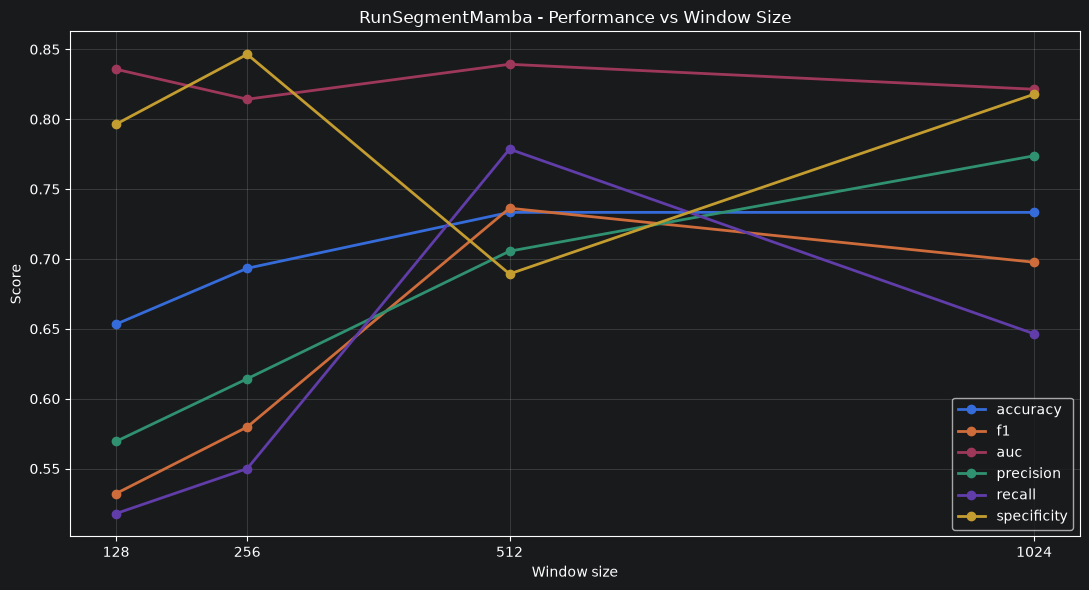


=== BEST WINDOW SIZE ===
Window size: 1024
Accuracy: 0.7333
F1: 0.6977
AUC: 0.8214


In [2]:
# WINDOW SIZE - RunFullySegmentMamba

results = []
window_sizes = [128, 256, 512, 1024]

for w in window_sizes:

    print(f"\n=== Running experiment with window_size={w} ===")

    runner = RunFullySegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        window_size=w,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=50,
        batch_size=32,
        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/window_size/w_{w}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "window_size": w,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("window_size")

print("\n=== WINDOW SIZE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_segment_mamba_window_size_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["window_size"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(df["window_size"])

plt.xlabel("Window size")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Window Size")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST WINDOW SIZE ===")
print(f"Window size: {int(best['window_size'])}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")


=== Running experiment with window_size=2048 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.8374 | train_accuracy=0.5167 | train_f1=0.4082 | train_auc=0.5517 | train_precision=0.5000 | train_recall=0.3448 | train_specificity=0.6774 | val_loss=0.7238 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5536 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.7316 | train_accuracy=0.5000 | train_f1=0.6591 | train_auc=0.6563 | train_precision=0.4915 | train_recall=1.0000 | train_specificity=0.0323 | val_loss=0.6763 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5893 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.6754 | train_accuracy=0.5833 | train_f1=0.6479 | train_auc=0.6340 | train_precision=0.5476 | train_recall=0.7931 | train_specificity=0.3871 | val_loss=0.7199 | val_acc

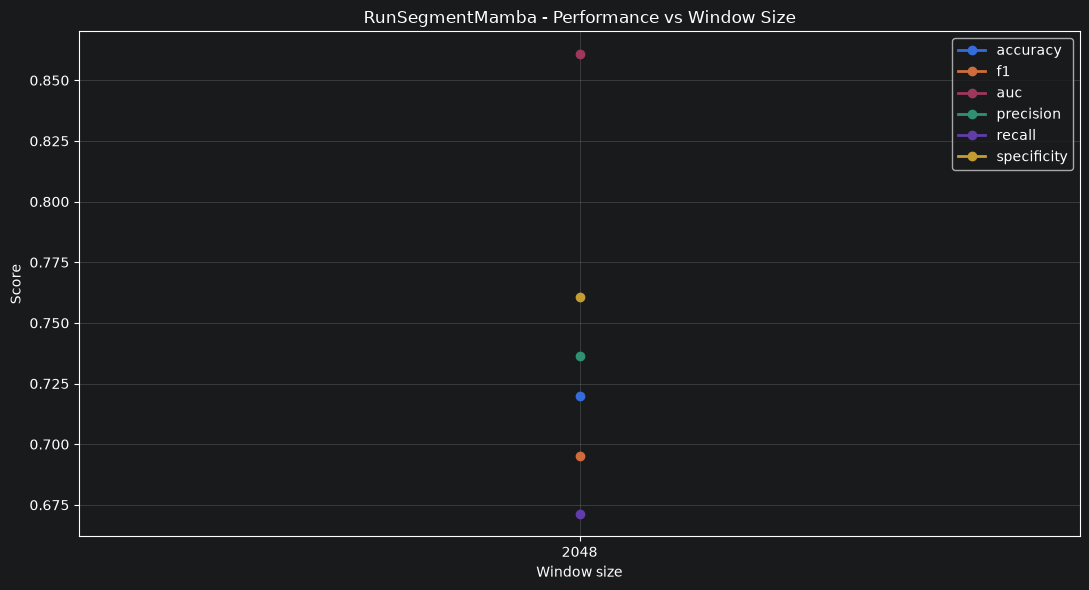


=== BEST WINDOW SIZE ===
Window size: 2048
Accuracy: 0.7200
F1: 0.6951
AUC: 0.8607


In [3]:
# WINDOW SIZE - RunFullySegmentMamba

results = []
window_sizes = [2048]

for w in window_sizes:

    print(f"\n=== Running experiment with window_size={w} ===")

    runner = RunFullySegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        window_size=w,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=50,
        batch_size=32,
        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/window_size/w_{w}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "window_size": w,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("window_size")

print("\n=== WINDOW SIZE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_segment_mamba_window_size_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["window_size"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(df["window_size"])

plt.xlabel("Window size")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Window Size")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST WINDOW SIZE ===")
print(f"Window size: {int(best['window_size'])}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")

In [ ]:
# EPOCHS - RunFullySegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

epochs = [25, 50, 100, 150, 200, 250]

for e in epochs:

    print(f"\n=== Running experiment with epoch={e} ===")

    runner = RunFullySegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        window_size=512,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=e,
        batch_size=32,
        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/epochs/e_{e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "epoch": e,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("epoch")

print("\n=== EPOCHS SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_segment_mamba_epochs_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["epoch"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(df["epoch"])

plt.xlabel("Epochs")
plt.ylabel("Score")
plt.title("RunFullySegmentMamba - Performance vs Epochs")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST EPOCH ===")
print(f"Epochs: {int(best['epoch'])}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")


=== Running experiment with epoch=25 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.0046 | train_accuracy=0.5167 | train_f1=0.4727 | train_auc=0.5373 | train_precision=0.5000 | train_recall=0.4483 | train_specificity=0.5806 | val_loss=0.7002 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.6786 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.7987 | train_accuracy=0.5500 | train_f1=0.5714 | train_auc=0.5006 | train_precision=0.5294 | train_recall=0.6207 | train_specificity=0.4839 | val_loss=0.8166 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6250 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.7984 | train_accuracy=0.4833 | train_f1=0.6437 | train_auc=0.5684 | train_precision=0.4828 | train_recall=0.9655 | train_specificity=0.0323 | val_loss=0.6642 | val_accuracy=0.


=== Running experiment with learning_rate=0.01 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.6753 | train_accuracy=0.5833 | train_f1=0.5614 | train_auc=0.5451 | train_precision=0.5714 | train_recall=0.5517 | train_specificity=0.6129 | val_loss=0.7888 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.7143 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=1.8170 | train_accuracy=0.3833 | train_f1=0.3934 | train_auc=0.3348 | train_precision=0.3750 | train_recall=0.4138 | train_specificity=0.3548 | val_loss=1.7079 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7500 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=1.3361 | train_accuracy=0.5167 | train_f1=0.4912 | train_auc=0.5172 | train_precision=0.5000 | train_recall=0.4828 | train_specificity=0.5484 | val_loss=0.7937 | val_a

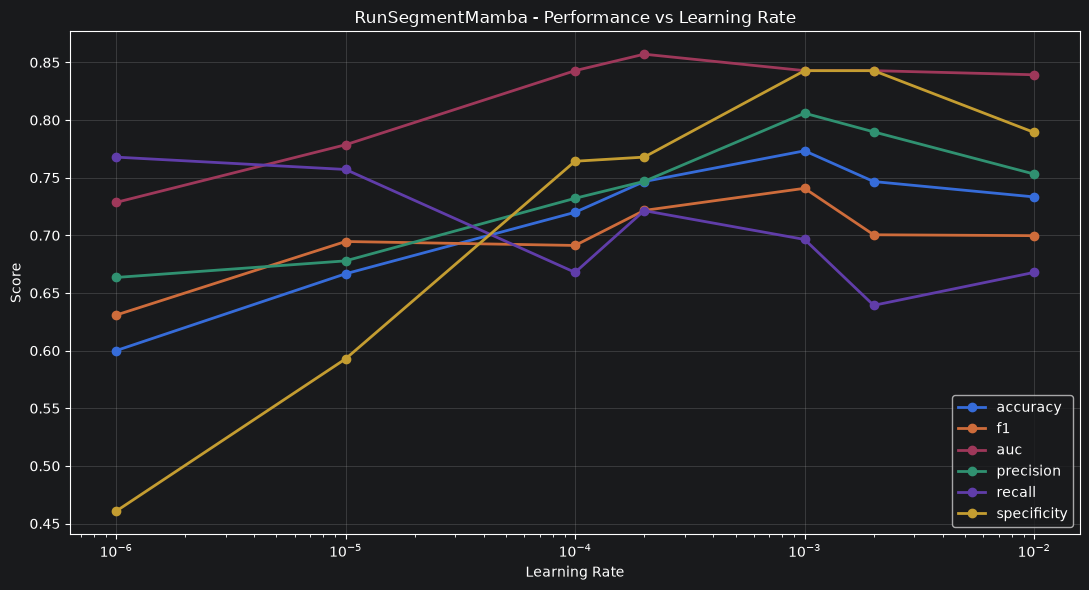


=== BEST LEARNING RATE ===
Learning Rate: 1.0e-03
Accuracy: 0.7733
F1: 0.7408
AUC: 0.8429
Precision: 0.8060
Recall: 0.6964
Specificity: 0.8429


In [5]:
# LEARNING RATE - RunFullySegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

learning_rates = [1e-2, 1e-3, 1e-4, 2e-3, 2e-4, 1e-5, 1e-6]

# =========================================================
# EXPERIMENTS
# =========================================================

for lr in learning_rates:

    print(f"\n=== Running experiment with learning_rate={lr} ===")

    runner = RunFullySegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[8],
        feature_names=("x", "y"),
        engineered_features=("pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=100,
        batch_size=32,
        learning_rate=lr,

        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/learning_rate/lr_{lr}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "learning_rate": lr,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("learning_rate")

print("\n=== LEARNING RATE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "segment_mamba_learning_rate_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["learning_rate"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xlabel("Learning Rate")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Learning Rate")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST LEARNING RATE ===")
print(f"Learning Rate: {best['learning_rate']:.1e}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


=== Running experiment with regularization=1e-08 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.8832 | train_accuracy=0.5833 | train_f1=0.5614 | train_auc=0.6196 | train_precision=0.5714 | train_recall=0.5517 | train_specificity=0.6129 | val_loss=0.5401 | val_accuracy=0.6667 | val_f1=0.7059 | val_auc=0.8571 | val_precision=0.6667 | val_recall=0.7500 | val_specificity=0.5714
Fold 01 | Epoch 02 | train_loss=0.8996 | train_accuracy=0.4333 | train_f1=0.3462 | train_auc=0.4438 | train_precision=0.3913 | train_recall=0.3103 | train_specificity=0.5484 | val_loss=0.7250 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.8214 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6581 | train_accuracy=0.6000 | train_f1=0.4000 | train_auc=0.7697 | train_precision=0.7273 | train_recall=0.2759 | train_specificity=0.9032 | val_loss=0.5102 | val

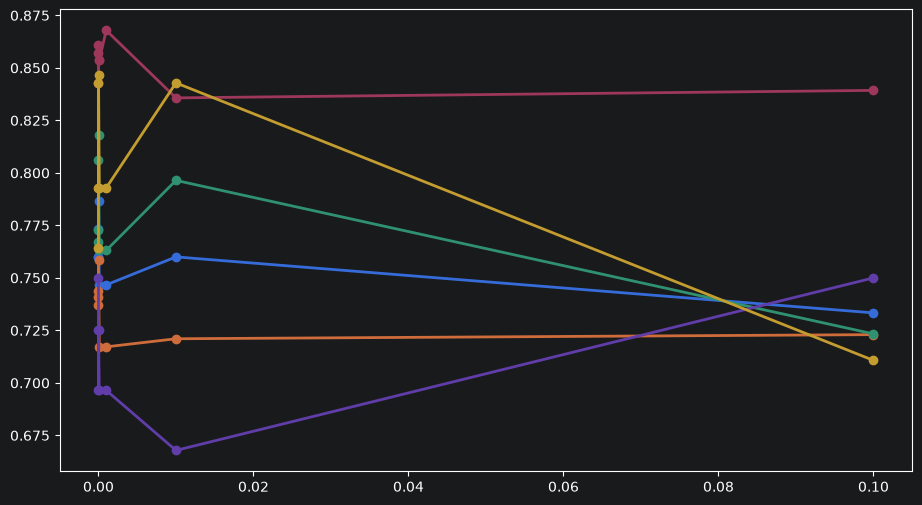

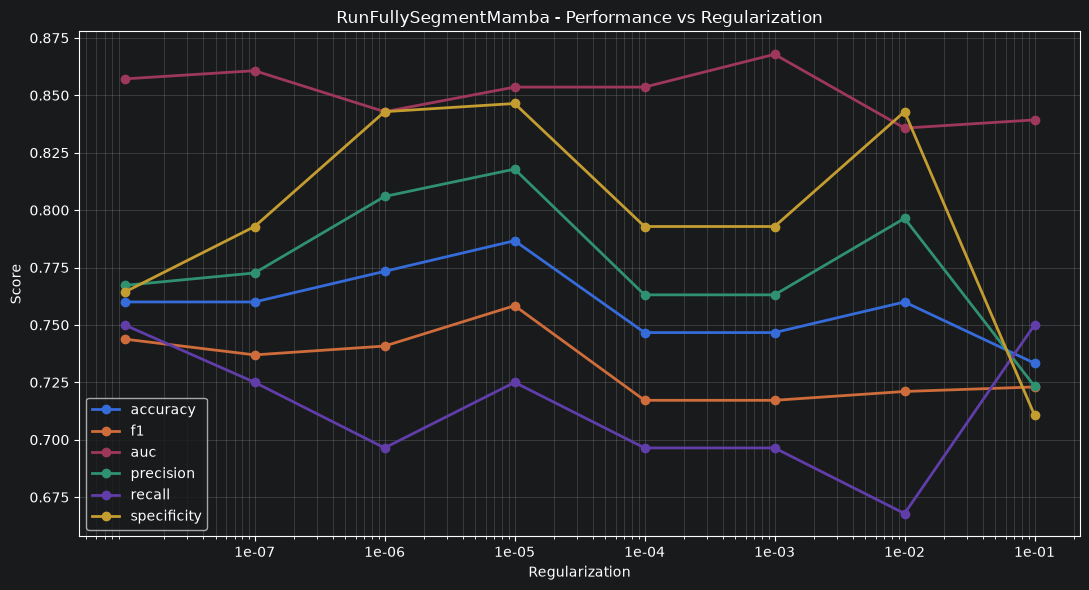


=== BEST REGULARIZATION ===
Regularization: 1.0e-05
Accuracy: 0.7867
F1: 0.7584
AUC: 0.8536
Precision: 0.8179
Recall: 0.7250
Specificity: 0.8464


In [6]:
# REGULARIZATION - RunFullySegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

regularization_values = [
    1e-8,
    1e-7,
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    1e-2,
    1e-1,
]

# =========================================================
# EXPERIMENTS
# =========================================================

for reg in regularization_values:

    print(f"\n=== Running experiment with regularization={reg} ===")

    runner = RunFullySegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[8],
        feature_names=("x", "y"),
        engineered_features=("pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=100,
        batch_size=32,
        learning_rate=1e-3,

        # REGOLARIZZAZIONE
        regularization=reg,

        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/"
            f"regularization/reg_{reg}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "regularization": reg,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("regularization")

print("\n=== REGULARIZATION SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_segment_mamba_regularization_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["regularization"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

# Scala logaritmica
plot_df = df[df["regularization"] > 0]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        plot_df["regularization"],
        plot_df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xticks(
    regularization_values[1:],
    [f"{x:.0e}" for x in regularization_values[1:]]
)

plt.xlabel("Regularization")
plt.ylabel("Score")
plt.title("RunFullySegmentMamba - Performance vs Regularization")

plt.grid(True, alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST REGULARIZATION ===")
print(f"Regularization: {best['regularization']:.1e}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


=== Running experiment with batch_size=8 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.0360 | train_accuracy=0.4167 | train_f1=0.2553 | train_auc=0.3582 | train_precision=0.3333 | train_recall=0.2069 | train_specificity=0.6129 | val_loss=0.5800 | val_accuracy=0.6667 | val_f1=0.7059 | val_auc=0.8393 | val_precision=0.6667 | val_recall=0.7500 | val_specificity=0.5714
Fold 01 | Epoch 02 | train_loss=0.6818 | train_accuracy=0.6167 | train_f1=0.6849 | train_auc=0.7086 | train_precision=0.5682 | train_recall=0.8621 | train_specificity=0.3871 | val_loss=0.6622 | val_accuracy=0.8000 | val_f1=0.7692 | val_auc=0.8214 | val_precision=1.0000 | val_recall=0.6250 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6154 | train_accuracy=0.6833 | train_f1=0.6122 | train_auc=0.7430 | train_precision=0.7500 | train_recall=0.5172 | train_specificity=0.8387 | val_loss=0.4908 | val_accurac

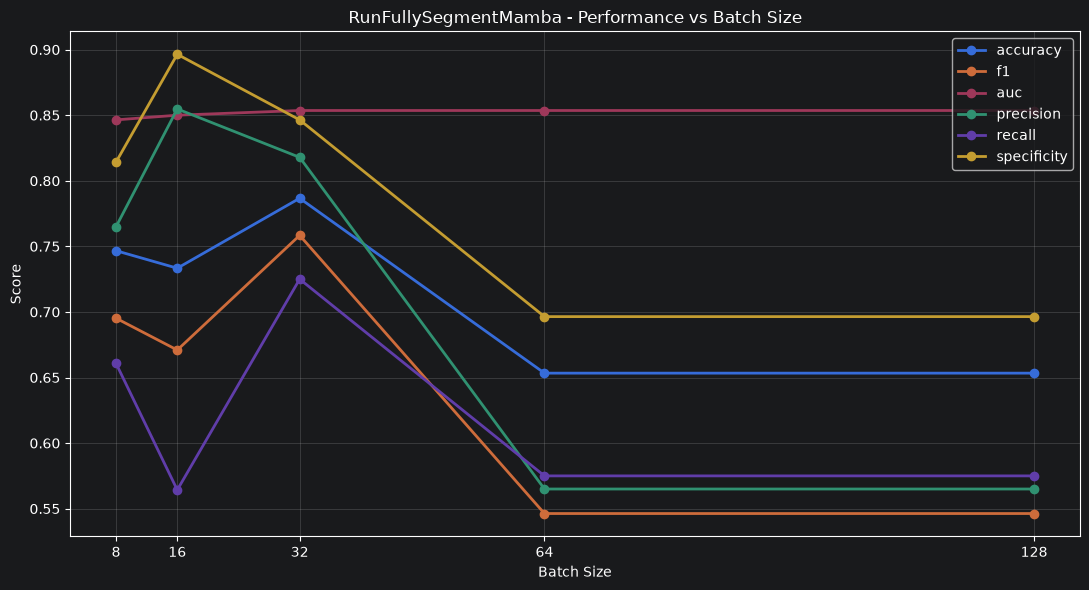


=== BEST BATCH SIZE ===
Batch Size: 32
Accuracy: 0.7867
F1: 0.7584
AUC: 0.8536
Precision: 0.8179
Recall: 0.7250
Specificity: 0.8464


In [7]:
# BATCH SIZE - RunFullySegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

batch_sizes = [8, 16, 32, 64, 128]

# =========================================================
# EXPERIMENTS
# =========================================================

for batch in batch_sizes:

    print(f"\n=== Running experiment with batch_size={batch} ===")

    runner = RunFullySegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[8],
        feature_names=("x", "y"),
        engineered_features=("pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=100,
        batch_size=batch,
        learning_rate=1e-3,

        # REGOLARIZZAZIONE
        regularization=1e-5,

        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/"
            f"batch_size/size_{batch}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "batch_size": batch,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("batch_size")

print("\n=== BATCH SIZE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_segment_mamba_batch_size_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["batch_size"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(batch_sizes)

plt.xlabel("Batch Size")
plt.ylabel("Score")
plt.title("RunFullySegmentMamba - Performance vs Batch Size")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST BATCH SIZE ===")
print(f"Batch Size: {int(best['batch_size'])}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


=== Running experiment with early_stopping_patience=5 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.8831 | train_accuracy=0.5833 | train_f1=0.5614 | train_auc=0.6196 | train_precision=0.5714 | train_recall=0.5517 | train_specificity=0.6129 | val_loss=0.5402 | val_accuracy=0.6667 | val_f1=0.7059 | val_auc=0.8571 | val_precision=0.6667 | val_recall=0.7500 | val_specificity=0.5714
Fold 01 | Epoch 02 | train_loss=0.8996 | train_accuracy=0.4333 | train_f1=0.3462 | train_auc=0.4438 | train_precision=0.3913 | train_recall=0.3103 | train_specificity=0.5484 | val_loss=0.7251 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.8214 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6581 | train_accuracy=0.6000 | train_f1=0.4000 | train_auc=0.7709 | train_precision=0.7273 | train_recall=0.2759 | train_specificity=0.9032 | val_loss=0.5104 

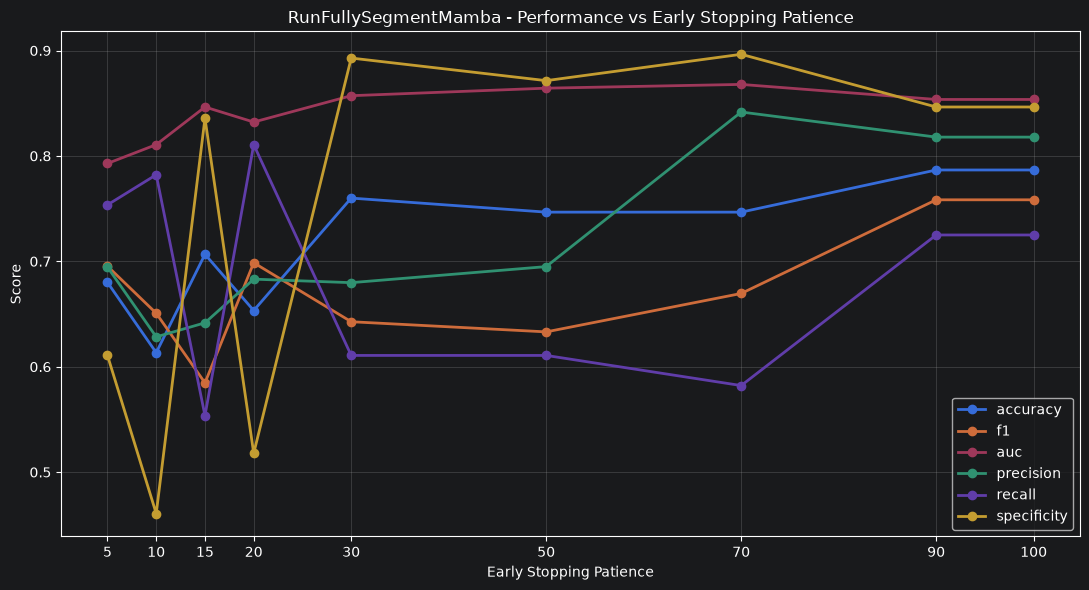


=== BEST EARLY STOPPING PATIENCE ===
Patience: 70
Accuracy: 0.7467
F1: 0.6695
AUC: 0.8679
Precision: 0.8417
Recall: 0.5821
Specificity: 0.8964


In [8]:
# EARLY STOPPING PATIENCE - RunFullySegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

patience_values = [5, 10, 15, 20, 30, 50, 70, 90, 100]

# =========================================================
# EXPERIMENTS
# =========================================================

for patience in patience_values:

    print(
        f"\n=== Running experiment with "
        f"early_stopping_patience={patience} ==="
    )

    runner = RunFullySegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[8],
        feature_names=("x", "y"),
        engineered_features=("pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=100,
        batch_size=32,
        learning_rate=1e-3,

        # REGOLARIZZAZIONE
        regularization=1e-5,

        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/"
            f"early_stopping/patience_{patience}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            # Metrica monitorata dall'early stopping
            "monitor_metric": "auc",

            # EARLY STOPPING
            "early_stopping_patience": patience,
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "early_stopping_patience": patience,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "early_stopping_patience"
)

print("\n=== EARLY STOPPING PATIENCE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_segment_mamba_early_stopping_patience_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["early_stopping_patience"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(patience_values)

plt.xlabel("Early Stopping Patience")
plt.ylabel("Score")
plt.title(
    "RunFullySegmentMamba - "
    "Performance vs Early Stopping Patience"
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST EARLY STOPPING PATIENCE ===")
print(
    f"Patience: "
    f"{int(best['early_stopping_patience'])}"
)
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


=== Running experiment with min_delta=0.0 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.8831 | train_accuracy=0.5833 | train_f1=0.5614 | train_auc=0.6196 | train_precision=0.5714 | train_recall=0.5517 | train_specificity=0.6129 | val_loss=0.5402 | val_accuracy=0.6667 | val_f1=0.7059 | val_auc=0.8571 | val_precision=0.6667 | val_recall=0.7500 | val_specificity=0.5714
Fold 01 | Epoch 02 | train_loss=0.8996 | train_accuracy=0.4333 | train_f1=0.3462 | train_auc=0.4438 | train_precision=0.3913 | train_recall=0.3103 | train_specificity=0.5484 | val_loss=0.7251 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.8214 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6581 | train_accuracy=0.6000 | train_f1=0.4000 | train_auc=0.7709 | train_precision=0.7273 | train_recall=0.2759 | train_specificity=0.9032 | val_loss=0.5104 | val_accura

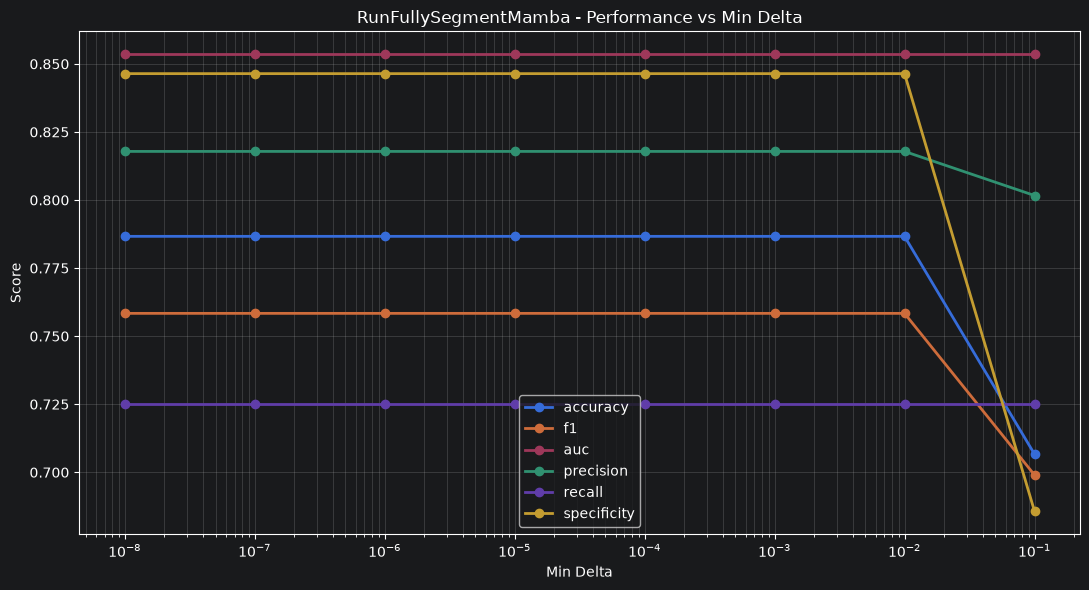


=== BEST MIN DELTA ===
Min Delta: 1.0e-01
Accuracy: 0.7067
F1: 0.6990
AUC: 0.8536
Precision: 0.8017
Recall: 0.7250
Specificity: 0.6857


In [4]:
# MIN DELTA - RunFullySegmentCNN
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

min_delta_values = [
    0.0,
    1e-8,
    1e-7,
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    1e-2,
    1e-1,
]

# =========================================================
# EXPERIMENTS
# =========================================================

for min_delta in min_delta_values:

    print(
        f"\n=== Running experiment with "
        f"min_delta={min_delta} ==="
    )

    runner = RunFullySegmentMamba(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[8],
        feature_names=("x", "y"),
        engineered_features=("pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=100,
        batch_size=32,
        learning_rate=1e-3,
        regularization=1e-5,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val seg)/"
            f"min_delta/min_delta_{min_delta}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            # =================================================
            # EARLY STOPPING
            # =================================================
            "monitor_metric": "auc",
            "early_stopping_patience": 90,
            "min_delta": min_delta,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "min_delta": min_delta,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("min_delta")

print("\n=== MIN DELTA SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "fully_segment_mamba_min_delta_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

# Separiamo lo zero perch﷿﷿﷿﷿﷿﷿ l'asse logaritmico non lo pu﷿﷿﷿﷿﷿﷿ rappresentare
plot_df = df[df["min_delta"] > 0]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        plot_df["min_delta"],
        plot_df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xlabel("Min Delta")
plt.ylabel("Score")
plt.title(
    "RunFullySegmentMamba - "
    "Performance vs Min Delta"
)

plt.grid(True, alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST MIN DELTA ===")
print(
    f"Min Delta: "
    f"{best['min_delta']:.1e}"
)

print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.8831 | train_accuracy=0.5833 | train_f1=0.5614 | train_auc=0.6196 | train_precision=0.5714 | train_recall=0.5517 | train_specificity=0.6129 | val_loss=0.5402 | val_accuracy=0.6667 | val_f1=0.7059 | val_auc=0.8571 | val_precision=0.6667 | val_recall=0.7500 | val_specificity=0.5714
Fold 01 | Epoch 02 | train_loss=0.8996 | train_accuracy=0.4333 | train_f1=0.3462 | train_auc=0.4438 | train_precision=0.3913 | train_recall=0.3103 | train_specificity=0.5484 | val_loss=0.7251 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.8214 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6581 | train_accuracy=0.6000 | train_f1=0.4000 | train_auc=0.7709 | train_precision=0.7273 | train_recall=0.2759 | train_specificity=0.9032 | val_loss=0.5104 | val_accuracy=0.8000 | val_f1=0.8000 | val_auc=0.8393 | va

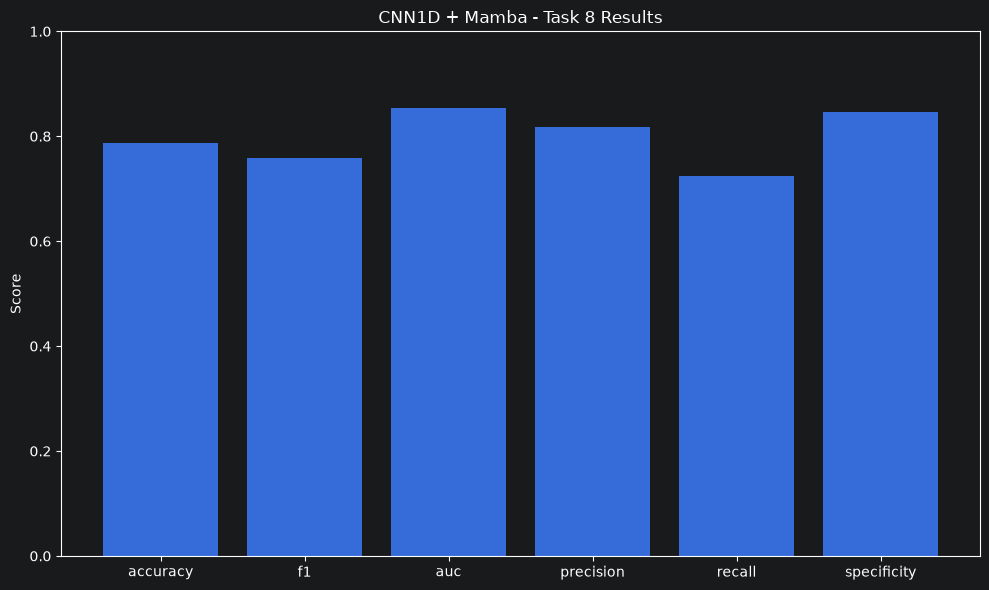

In [3]:
# =====================================
# RUN EXPERIMENT
# task 8 -> xy_pressure_derivative
# =====================================

runner = RunFullySegmentMamba(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[8],
    feature_names=("x", "y"),
    engineered_features=("pressure_derivative",),
    window_size=256,
    batch_size=32,
    epochs=100,
    learning_rate=1e-3,
    regularization=1e-5,
    n_splits=5,
    normalize=True,
    seed=42,
    device=("cuda" if torch.cuda.is_available() else "cpu"),
    output_dir=_project_path("experiments/cnn1D + mamba/raw_segment(train_seg - val_seg)/task_8/xy_pressure_derivative"),
    training_cfg={
        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
        "monitor_metric": "auc",
        "early_stopping_patience": 90,
        "min_delta": 0.0,
        "results_writer": "csv",
        "save_metrics": True,
    },
)

summary = runner.run()

# =====================================
# RESULTS
# =====================================

averages = summary["averages"]

print("\n=== FINAL RESULTS ===")

print(f"Accuracy:    {averages['val_accuracy']:.4f}")
print(f"F1 Score:    {averages['val_f1']:.4f}")
print(f"AUC:         {averages['val_auc']:.4f}")
print(f"Precision:   {averages['val_precision']:.4f}")
print(f"Recall:      {averages['val_recall']:.4f}")
print(f"Specificity: {averages['val_specificity']:.4f}")

# =====================================
# BUILD DATAFRAME
# =====================================

df = pd.DataFrame([{
    "accuracy": averages["val_accuracy"],
    "f1": averages["val_f1"],
    "auc": averages["val_auc"],
    "precision": averages["val_precision"],
    "recall": averages["val_recall"],
    "specificity": averages["val_specificity"],
}])

# =====================================
# PLOT
# =====================================

metrics = [
    "accuracy",
    "f1",
    "auc",
    "precision",
    "recall",
    "specificity",
]

values = [
    averages[f"val_{m}"]
    for m in metrics
]

plt.figure(figsize=(10, 6))

plt.bar(
    metrics,
    values,
)

plt.ylim(0, 1)

plt.ylabel("Score")

plt.title(
    "CNN1D + Mamba - Task 8 Results"
)

plt.tight_layout()

plt.show()
